In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [3]:
import os

DATA_ROOT = "/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA"

TRAIN_ROOT = os.path.join(
    DATA_ROOT,
    "ASVspoof2019_LA_train"
)

DEV_ROOT = os.path.join(
    DATA_ROOT,
    "ASVspoof2019_LA_dev"
)

EVAL_ROOT = os.path.join(
    DATA_ROOT,
    "ASVspoof2019_LA_eval"
)

PROTOCOL_ROOT = os.path.join(
    DATA_ROOT,
    "ASVspoof2019_LA_cm_protocols"
)

print("DATA_ROOT:", DATA_ROOT)
print("TRAIN_ROOT:", TRAIN_ROOT)
print("DEV_ROOT:", DEV_ROOT)
print("EVAL_ROOT:", EVAL_ROOT)
print("PROTOCOL_ROOT:", PROTOCOL_ROOT)

DATA_ROOT: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA
TRAIN_ROOT: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train
DEV_ROOT: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_dev
EVAL_ROOT: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_eval
PROTOCOL_ROOT: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols


In [4]:
print("Train exists:", os.path.exists(TRAIN_ROOT))
print("Dev exists:", os.path.exists(DEV_ROOT))
print("Eval exists:", os.path.exists(EVAL_ROOT))
print("Protocols exist:", os.path.exists(PROTOCOL_ROOT))

Train exists: True
Dev exists: True
Eval exists: True
Protocols exist: True


In [5]:
!ls -lah "$TRAIN_ROOT"

total 20K
drwxr-xr-x 3 nobody nogroup   0 Dec 13  2025 .
drwxr-xr-x 8 nobody nogroup   0 Dec 13  2025 ..
drwxr-xr-x 2 nobody nogroup   0 Dec 13  2025 flac
-rwxr-xr-x 1 nobody nogroup 20K Jun 21  2022 LICENSE.txt


In [7]:
TRAIN_AUDIO = os.path.join(TRAIN_ROOT, "flac")

print("Training audio path:")
print(TRAIN_AUDIO)

Training audio path:
/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac


In [8]:
!ls "$TRAIN_AUDIO" | head

LA_T_1000137.flac
LA_T_1000406.flac
LA_T_1000648.flac
LA_T_1000824.flac
LA_T_1001074.flac
LA_T_1001114.flac
LA_T_1001169.flac
LA_T_1001718.flac
LA_T_1001871.flac
LA_T_1002656.flac
ls: write error: Broken pipe


In [9]:
DEV_AUDIO = os.path.join(DEV_ROOT, "flac")
EVAL_AUDIO = os.path.join(EVAL_ROOT, "flac")
print("Dev audio exists:", os.path.exists(DEV_AUDIO))
print("Eval audio exists:", os.path.exists(EVAL_AUDIO))

Dev audio exists: True
Eval audio exists: True


In [10]:
!ls "$DEV_AUDIO" | head

LA_D_1000265.flac
LA_D_1000752.flac
LA_D_1001095.flac
LA_D_1002130.flac
LA_D_1002200.flac
LA_D_1002318.flac
LA_D_1002626.flac
LA_D_1002910.flac
LA_D_1003356.flac
LA_D_1003673.flac
ls: write error: Broken pipe


In [11]:
!ls "$EVAL_AUDIO" | head

LA_E_1000147.flac
LA_E_1000273.flac
LA_E_1000791.flac
LA_E_1000841.flac
LA_E_1000989.flac
LA_E_1001227.flac
LA_E_1001232.flac
LA_E_1001320.flac
LA_E_1001476.flac
LA_E_1001893.flac
ls: write error: Broken pipe


In [12]:
!ls -lah "$PROTOCOL_ROOT"

total 3.9M
drwxr-xr-x 2 nobody nogroup    0 Dec 13  2025 .
drwxr-xr-x 8 nobody nogroup    0 Dec 13  2025 ..
-rwxr-xr-x 1 nobody nogroup 804K Jun 21  2022 ASVspoof2019.LA.cm.dev.trl.txt
-rwxr-xr-x 1 nobody nogroup 2.3M Jun 21  2022 ASVspoof2019.LA.cm.eval.trl.txt
-rwxr-xr-x 1 nobody nogroup 821K Jun 21  2022 ASVspoof2019.LA.cm.train.trn.txt


In [13]:
protocol_files = os.listdir(PROTOCOL_ROOT)

for file in protocol_files:
    print(file)

ASVspoof2019.LA.cm.eval.trl.txt
ASVspoof2019.LA.cm.train.trn.txt
ASVspoof2019.LA.cm.dev.trl.txt


In [14]:
train_protocol_candidates = [
    f for f in os.listdir(PROTOCOL_ROOT)
    if "train" in f.lower()
]

print(train_protocol_candidates)

['ASVspoof2019.LA.cm.train.trn.txt']


In [15]:
TRAIN_PROTOCOL = os.path.join(
    PROTOCOL_ROOT,
    train_protocol_candidates[0]
)

print(TRAIN_PROTOCOL)

/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt


In [16]:
!head -10 "$TRAIN_PROTOCOL"

LA_0079 LA_T_1138215 - - bonafide
LA_0079 LA_T_1271820 - - bonafide
LA_0079 LA_T_1272637 - - bonafide
LA_0079 LA_T_1276960 - - bonafide
LA_0079 LA_T_1341447 - - bonafide
LA_0079 LA_T_1363611 - - bonafide
LA_0079 LA_T_1596451 - - bonafide
LA_0079 LA_T_1608170 - - bonafide
LA_0079 LA_T_1684951 - - bonafide
LA_0079 LA_T_1699801 - - bonafide


In [17]:
import pandas as pd
import numpy as np
import os

In [18]:
train_df = pd.read_csv(
    TRAIN_PROTOCOL,
    sep=r"\s+",
    header=None
)

train_df.sample(10)

,0,1,2,3,4
2476,LA_0098,LA_T_2607307,-,-,bonafide
241,LA_0080,LA_T_8739453,-,-,bonafide
6775,LA_0081,LA_T_2259200,-,A02,spoof
20416,LA_0092,LA_T_9674583,-,A05,spoof
17383,LA_0096,LA_T_9238217,-,A04,spoof
10196,LA_0079,LA_T_1801559,-,A03,spoof
16830,LA_0094,LA_T_1355755,-,A04,spoof
22467,LA_0083,LA_T_7107753,-,A06,spoof
1185,LA_0088,LA_T_2707835,-,-,bonafide
7996,LA_0087,LA_T_6051680,-,A02,spoof


In [19]:
train_df.columns = [
    "speaker",
    "file_id",
    "system_id",
    "key",
    "label"
]

train_df.head()

,speaker,file_id,system_id,key,label
0,LA_0079,LA_T_1138215,-,-,bonafide
1,LA_0079,LA_T_1271820,-,-,bonafide
2,LA_0079,LA_T_1272637,-,-,bonafide
3,LA_0079,LA_T_1276960,-,-,bonafide
4,LA_0079,LA_T_1341447,-,-,bonafide


In [20]:
train_df["target"] = train_df["label"].map({
    "bonafide": 0,
    "spoof": 1
})
train_df[["file_id", "label", "target"]].sample(10)

,file_id,label,target
8796,LA_T_8136900,spoof,1
7611,LA_T_5870308,spoof,1
6648,LA_T_4766453,spoof,1
11769,LA_T_4554352,spoof,1
24549,LA_T_6734483,spoof,1
21439,LA_T_3400735,spoof,1
24005,LA_T_8839871,spoof,1
23379,LA_T_5859529,spoof,1
684,LA_T_4124955,bonafide,0
19098,LA_T_9680097,spoof,1


In [21]:
print(train_df["label"].value_counts())

label
spoof       22800
bonafide     2580
Name: count, dtype: int64


In [22]:
print(train_df["target"].value_counts())

target
1    22800
0     2580
Name: count, dtype: int64


In [23]:
print(
    train_df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

label
spoof       89.83
bonafide    10.17
Name: proportion, dtype: float64


In [24]:
train_df["audio_path"] = train_df["file_id"].apply(
    lambda x: os.path.join(
        TRAIN_AUDIO,
        x + ".flac"
    )
)
train_df[["file_id", "audio_path"]].head()

,file_id,audio_path
0,LA_T_1138215,/kaggle/input/datasets/awsaf49/asvpoof-2019-da...
1,LA_T_1271820,/kaggle/input/datasets/awsaf49/asvpoof-2019-da...
2,LA_T_1272637,/kaggle/input/datasets/awsaf49/asvpoof-2019-da...
3,LA_T_1276960,/kaggle/input/datasets/awsaf49/asvpoof-2019-da...
4,LA_T_1341447,/kaggle/input/datasets/awsaf49/asvpoof-2019-da...


In [25]:
train_df["exists"] = train_df["audio_path"].apply(
    os.path.exists
)

print(train_df["exists"].value_counts())

exists
True    25380
Name: count, dtype: int64


In [26]:
import librosa
import librosa.display
import soundfile as sf

In [27]:
sample = train_df.iloc[0]

audio_path = sample["audio_path"]
label = sample["label"]

print("File:", audio_path)
print("Label:", label)

File: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1138215.flac
Label: bonafide


In [28]:
audio, sr = librosa.load(
    audio_path,
    sr=None
)

print("Sampling rate:", sr)
print("Number of samples:", len(audio))
print("Duration:", len(audio) / sr, "seconds")

Sampling rate: 16000
Number of samples: 55329
Duration: 3.4580625 seconds


In [29]:
from IPython.display import Audio

Audio(audio, rate=sr)

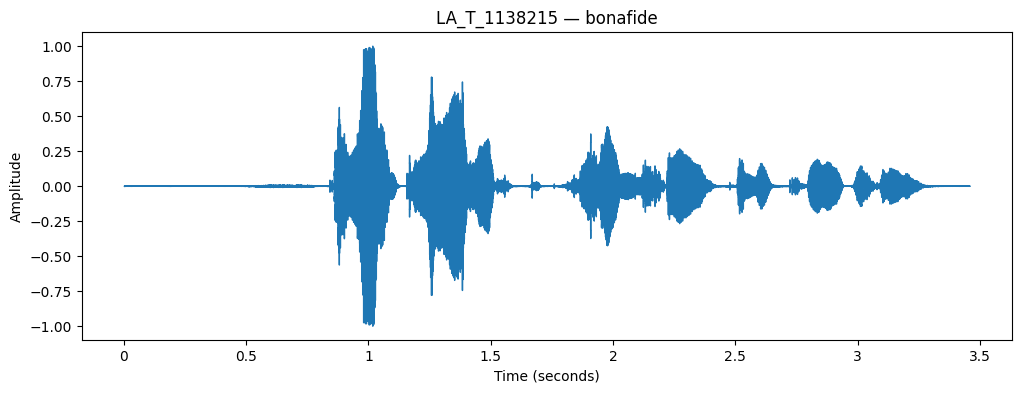

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

librosa.display.waveshow(
    audio,
    sr=sr
)

plt.title(
    f"{sample['file_id']} — {sample['label']}"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

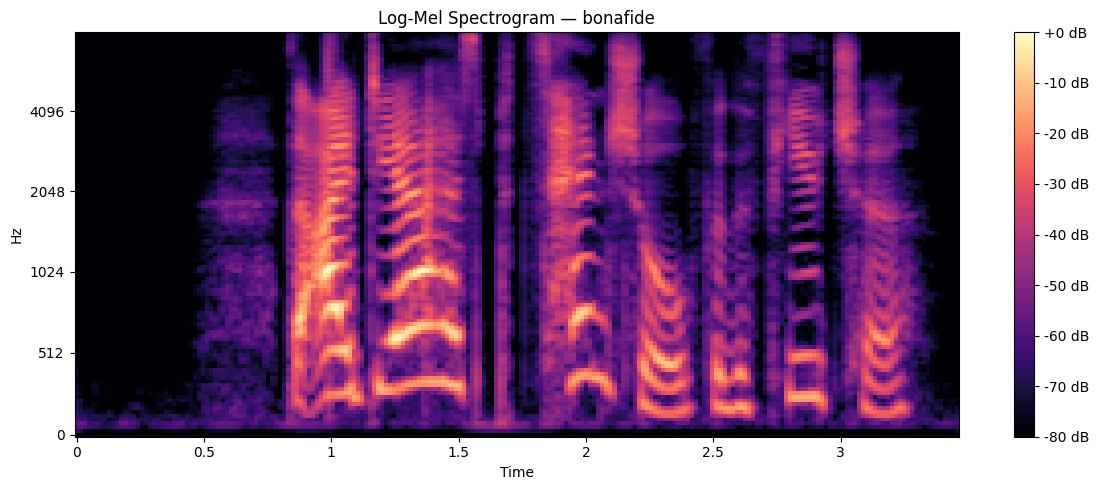

In [31]:
mel = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_mels=128,
    n_fft=1024,
    hop_length=256
)
log_mel = librosa.power_to_db(
    mel,
    ref=np.max
)
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    log_mel,
    sr=sr,
    hop_length=256,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")

plt.title(
    f"Log-Mel Spectrogram — {sample['label']}"
)

plt.tight_layout()
plt.show()

In [32]:
print("Training samples:", len(train_df))
dev_protocol_candidates = [
    f for f in os.listdir(PROTOCOL_ROOT)
    if "dev" in f.lower()
]

print(dev_protocol_candidates)

Training samples: 25380
['ASVspoof2019.LA.cm.dev.trl.txt']


In [33]:
DEV_PROTOCOL = os.path.join(
    PROTOCOL_ROOT,
    dev_protocol_candidates[0]
)

print(DEV_PROTOCOL)

/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt


In [34]:
!head -10 "$DEV_PROTOCOL"

LA_0069 LA_D_1047731 - - bonafide
LA_0069 LA_D_1105538 - - bonafide
LA_0069 LA_D_1125976 - - bonafide
LA_0069 LA_D_1293230 - - bonafide
LA_0069 LA_D_1340209 - - bonafide
LA_0069 LA_D_1376638 - - bonafide
LA_0069 LA_D_1377420 - - bonafide
LA_0069 LA_D_1403371 - - bonafide
LA_0069 LA_D_1590530 - - bonafide
LA_0069 LA_D_1595036 - - bonafide


In [35]:
eval_protocol_candidates = [
    f for f in os.listdir(PROTOCOL_ROOT)
    if "eval" in f.lower()
]

print(eval_protocol_candidates)

['ASVspoof2019.LA.cm.eval.trl.txt']


In [36]:
EVAL_PROTOCOL = os.path.join(
    PROTOCOL_ROOT,
    eval_protocol_candidates[0]
)

print(EVAL_PROTOCOL)

/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt


In [37]:
import os

DATA_ROOT = "/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA"

print("DATA ROOT:")
print(DATA_ROOT)

print("\nContents:")
for item in os.listdir(DATA_ROOT):
    print(item)

DATA ROOT:
/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA

Contents:
ASVspoof2019_LA_dev
ASVspoof2019_LA_train
ASVspoof2019_LA_cm_protocols
ASVspoof2019_LA_eval
ASVspoof2019_LA_asv_protocols
README.LA.txt
ASVspoof2019_LA_asv_scores


In [38]:
TRAIN_AUDIO = "/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac"

DEV_AUDIO = "/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_dev/flac"

EVAL_AUDIO = "/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_eval/flac"

PROTOCOL_DIR = "/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols"

In [39]:
paths = {
    "Train audio": TRAIN_AUDIO,
    "Dev audio": DEV_AUDIO,
    "Eval audio": EVAL_AUDIO,
    "Protocol": PROTOCOL_DIR
}

for name, path in paths.items():
    print(f"{name}:")
    print(path)
    print("Exists:", os.path.exists(path))
    print()

Train audio:
/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac
Exists: True

Dev audio:
/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_dev/flac
Exists: True

Eval audio:
/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_eval/flac
Exists: True

Protocol:
/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols
Exists: True



In [40]:
print("Protocol files:")

for f in os.listdir(PROTOCOL_DIR):
    print(f)

Protocol files:
ASVspoof2019.LA.cm.eval.trl.txt
ASVspoof2019.LA.cm.train.trn.txt
ASVspoof2019.LA.cm.dev.trl.txt


In [41]:
TRAIN_PROTOCOL = os.path.join(
    PROTOCOL_DIR,
    "ASVspoof2019.LA.cm.train.trn.txt"
)

DEV_PROTOCOL = os.path.join(
    PROTOCOL_DIR,
    "ASVspoof2019.LA.cm.dev.trl.txt"
)

EVAL_PROTOCOL = os.path.join(
    PROTOCOL_DIR,
    "ASVspoof2019.LA.cm.eval.trl.txt"
)

print(TRAIN_PROTOCOL)
print(DEV_PROTOCOL)
print(EVAL_PROTOCOL)

/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt
/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt
/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt


In [42]:
!pip install -q transformers librosa soundfile tqdm

In [43]:
import os
import numpy as np
import torch
import librosa

from tqdm.auto import tqdm
from transformers import Wav2Vec2Model, Wav2Vec2FeatureExtractor

In [45]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", DEVICE)

feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(
    "facebook/wav2vec2-base"
)

wav2vec2 = Wav2Vec2Model.from_pretrained(
    "facebook/wav2vec2-base"
).to(DEVICE)

wav2vec2.eval()

for param in wav2vec2.parameters():
    param.requires_grad = False

print("wav2vec2 loaded successfully.")

Using device: cuda


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


wav2vec2 loaded successfully.


In [46]:
SR = 16000
LEN = 64000
print("Sampling rate:", SR)
print("Samples per clip:", LEN)
print("Duration:", LEN / SR, "seconds")

Sampling rate: 16000
Samples per clip: 64000
Duration: 4.0 seconds


In [47]:
def load_audio(path):
    y, _ = librosa.load(
        path,
        sr=SR,
        mono=True
    )

    # Pad short audio
    if len(y) < LEN:
        y = np.pad(
            y,
            (0, LEN - len(y))
        )

    # Crop long audio
    return y[:LEN]

In [48]:
import glob

test_files = glob.glob(
    os.path.join(TRAIN_AUDIO, "*.flac")
)

print("Number of train audio files:", len(test_files))

test_file = test_files[0]

print("\nTest file:")
print(test_file)

audio = load_audio(test_file)

print("\nAudio shape:", audio.shape)
print("Audio dtype:", audio.dtype)
print("Duration:", len(audio) / SR, "seconds")

Number of train audio files: 25380

Test file:
/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac/LA_T_9552332.flac

Audio shape: (64000,)
Audio dtype: float32
Duration: 4.0 seconds


In [49]:
inputs = feature_extractor(
    audio,
    sampling_rate=SR,
    return_tensors="pt"
)

input_values = inputs.input_values.to(DEVICE)

with torch.no_grad():
    output = wav2vec2(
        input_values,
        output_hidden_states=True
    )

print("Number of hidden states:", len(output.hidden_states))

for i, h in enumerate(output.hidden_states):
    print(f"Layer {i}: {h.shape}")

Number of hidden states: 13
Layer 0: torch.Size([1, 199, 768])
Layer 1: torch.Size([1, 199, 768])
Layer 2: torch.Size([1, 199, 768])
Layer 3: torch.Size([1, 199, 768])
Layer 4: torch.Size([1, 199, 768])
Layer 5: torch.Size([1, 199, 768])
Layer 6: torch.Size([1, 199, 768])
Layer 7: torch.Size([1, 199, 768])
Layer 8: torch.Size([1, 199, 768])
Layer 9: torch.Size([1, 199, 768])
Layer 10: torch.Size([1, 199, 768])
Layer 11: torch.Size([1, 199, 768])
Layer 12: torch.Size([1, 199, 768])


In [50]:
features = torch.stack(
    [h.mean(dim=1) for h in output.hidden_states],
    dim=1
)

print("Feature shape:", features.shape)

Feature shape: torch.Size([1, 13, 768])


In [51]:
features = features[0]

print("Single clip feature shape:", features.shape)

Single clip feature shape: torch.Size([13, 768])


In [52]:
CACHE_DIR = "/kaggle/working/rakshavoice_features"

os.makedirs(CACHE_DIR, exist_ok=True)

print("Cache directory:")
print(CACHE_DIR)

Cache directory:
/kaggle/working/rakshavoice_features


In [53]:
def read_protocol(proto_path):
    names = []
    labels = []

    with open(proto_path, "r") as f:
        for line in f:
            parts = line.split()

            names.append(parts[1])

            # 0 = bonafide
            # 1 = spoof
            labels.append(
                0 if parts[-1] == "bonafide" else 1
            )

    return names, np.array(labels, dtype=np.int64)

In [54]:
names, labels = read_protocol(TRAIN_PROTOCOL)

print("Number of protocol entries:", len(names))
print("First 5 names:", names[:5])
print("First 5 labels:", labels[:5])

Number of protocol entries: 25380
First 5 names: ['LA_T_1138215', 'LA_T_1271820', 'LA_T_1272637', 'LA_T_1276960', 'LA_T_1341447']
First 5 labels: [0 0 0 0 0]


In [55]:
missing = []

for name in names[:500]:
    path = os.path.join(TRAIN_AUDIO, name + ".flac")

    if not os.path.exists(path):
        missing.append(path)

print("Checked:", min(500, len(names)))
print("Missing:", len(missing))

if missing:
    print("\nFirst missing files:")
    print(*missing[:10], sep="\n")

Checked: 500
Missing: 0


In [56]:
def extract_features(
    audio_dir,
    proto_path,
    out_prefix,
    limit=None,
    batch_size=16
):
    names, labels = read_protocol(proto_path)

    if limit is not None:
        names = names[:limit]
        labels = labels[:limit]

    n = len(names)

    # 13 wav2vec2 hidden states × 768 dimensions
    X = np.zeros(
        (n, 13, 768),
        dtype=np.float16
    )

    print("Total clips:", n)
    print("Batch size:", batch_size)
    print("Output shape:", X.shape)

    for start in tqdm(
        range(0, n, batch_size),
        desc=f"Extracting {os.path.basename(out_prefix)}"
    ):

        batch_names = names[start:start + batch_size]

        batch_audio = []

        for name in batch_names:
            path = os.path.join(
                audio_dir,
                name + ".flac"
            )

            batch_audio.append(
                load_audio(path)
            )

        inputs = feature_extractor(
            batch_audio,
            sampling_rate=SR,
            return_tensors="pt",
            padding=True
        )

        input_values = inputs.input_values.to(DEVICE)

        with torch.no_grad():
            outputs = wav2vec2(
                input_values,
                output_hidden_states=True
            )

        batch_features = torch.stack(
            [
                h.mean(dim=1)
                for h in outputs.hidden_states
            ],
            dim=1
        )

        X[
            start:start + len(batch_names)
        ] = (
            batch_features
            .half()
            .cpu()
            .numpy()
        )

    X_path = out_prefix + "_X.npy"
    y_path = out_prefix + "_y.npy"

    np.save(X_path, X)
    np.save(y_path, labels)

    print("\nExtraction complete!")
    print("X saved:", X_path)
    print("y saved:", y_path)

    print("X shape:", X.shape)
    print("y shape:", labels.shape)

    return X, labels

In [57]:
train_test_prefix = os.path.join(
    CACHE_DIR,
    "train_500"
)

X_test, y_test = extract_features(
    audio_dir=TRAIN_AUDIO,
    proto_path=TRAIN_PROTOCOL,
    out_prefix=train_test_prefix,
    limit=500,
    batch_size=16
)

Total clips: 500
Batch size: 16
Output shape: (500, 13, 768)


Extracting train_500:   0%|          | 0/32 [00:00<?, ?it/s]


Extraction complete!
X saved: /kaggle/working/rakshavoice_features/train_500_X.npy
y saved: /kaggle/working/rakshavoice_features/train_500_y.npy
X shape: (500, 13, 768)
y shape: (500,)


In [58]:
print("X shape:", X_test.shape)
print("y shape:", y_test.shape)

print("X dtype:", X_test.dtype)
print("y dtype:", y_test.dtype)

print("X file exists:",
      os.path.exists(train_test_prefix + "_X.npy"))

print("y file exists:",
      os.path.exists(train_test_prefix + "_y.npy"))

X shape: (500, 13, 768)
y shape: (500,)
X dtype: float16
y dtype: int64
X file exists: True
y file exists: True


In [59]:
unique, counts = np.unique(
    y_test,
    return_counts=True
)

print("Label distribution:")

for label, count in zip(unique, counts):
    name = "bonafide" if label == 0 else "spoof"
    print(
        f"{label} ({name}): {count}"
    )

Label distribution:
0 (bonafide): 500


In [60]:
print("Minimum:", X_test.min())
print("Maximum:", X_test.max())
print("Mean:", X_test.mean())
print("Std:", X_test.std())
print("NaN:", np.isnan(X_test).sum())
print("Inf:", np.isinf(X_test).sum())

Minimum: -2.404
Maximum: 1.713
Mean: -0.001418
Std: inf
NaN: 0
Inf: 0


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:208: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)


In [61]:
TRAIN_PREFIX = os.path.join(
    CACHE_DIR,
    "train"
)

X_train, y_train = extract_features(
    audio_dir=TRAIN_AUDIO,
    proto_path=TRAIN_PROTOCOL,
    out_prefix=TRAIN_PREFIX,
    limit=None,
    batch_size=16
)

Total clips: 25380
Batch size: 16
Output shape: (25380, 13, 768)


Extracting train:   0%|          | 0/1587 [00:00<?, ?it/s]


Extraction complete!
X saved: /kaggle/working/rakshavoice_features/train_X.npy
y saved: /kaggle/working/rakshavoice_features/train_y.npy
X shape: (25380, 13, 768)
y shape: (25380,)


In [62]:
DEV_PREFIX = os.path.join(
    CACHE_DIR,
    "dev"
)

X_dev, y_dev = extract_features(
    audio_dir=DEV_AUDIO,
    proto_path=DEV_PROTOCOL,
    out_prefix=DEV_PREFIX,
    limit=None,
    batch_size=16
)

Total clips: 24844
Batch size: 16
Output shape: (24844, 13, 768)


Extracting dev:   0%|          | 0/1553 [00:00<?, ?it/s]


Extraction complete!
X saved: /kaggle/working/rakshavoice_features/dev_X.npy
y saved: /kaggle/working/rakshavoice_features/dev_y.npy
X shape: (24844, 13, 768)
y shape: (24844,)


In [63]:
def extract_random_features(
    audio_dir,
    proto_path,
    out_prefix,
    n_samples=20000,
    seed=42,
    batch_size=16
):
    names, labels = read_protocol(proto_path)

    # Reproducible random sampling
    rng = np.random.default_rng(seed)

    n_samples = min(n_samples, len(names))

    indices = rng.choice(
        len(names),
        size=n_samples,
        replace=False
    )

    names = [names[i] for i in indices]
    labels = labels[indices]

    X = np.zeros(
        (n_samples, 13, 768),
        dtype=np.float16
    )

    print("Random samples:", n_samples)
    print("Seed:", seed)
    print("Output shape:", X.shape)

    for start in tqdm(
        range(0, n_samples, batch_size),
        desc="Extracting random eval features"
    ):
        batch_names = names[start:start + batch_size]

        batch_audio = []

        for name in batch_names:
            path = os.path.join(
                audio_dir,
                name + ".flac"
            )

            batch_audio.append(load_audio(path))

        inputs = feature_extractor(
            batch_audio,
            sampling_rate=SR,
            return_tensors="pt",
            padding=True
        )

        input_values = inputs.input_values.to(DEVICE)

        with torch.no_grad():
            outputs = wav2vec2(
                input_values,
                output_hidden_states=True
            )

        batch_features = torch.stack(
            [
                h.mean(dim=1)
                for h in outputs.hidden_states
            ],
            dim=1
        )

        X[
            start:start + len(batch_names)
        ] = (
            batch_features
            .half()
            .cpu()
            .numpy()
        )

    np.save(out_prefix + "_X.npy", X)
    np.save(out_prefix + "_y.npy", labels)

    print("\nExtraction complete!")
    print("X shape:", X.shape)
    print("y shape:", labels.shape)

    return X, labels

In [64]:
EVAL_PREFIX = os.path.join(
    CACHE_DIR,
    "eval_random_20000"
)

X_eval, y_eval = extract_random_features(
    audio_dir=EVAL_AUDIO,
    proto_path=EVAL_PROTOCOL,
    out_prefix=EVAL_PREFIX,
    n_samples=20000,
    seed=42,
    batch_size=16
)

Random samples: 20000
Seed: 42
Output shape: (20000, 13, 768)


Extracting random eval features:   0%|          | 0/1250 [00:00<?, ?it/s]


Extraction complete!
X shape: (20000, 13, 768)
y shape: (20000,)


In [70]:
print("TRAIN:")
print(X_train.shape, y_train.shape)

print("\nDEV:")
print(X_dev.shape, y_dev.shape)

print("\nEVAL:")
print(X_eval.shape, y_eval.shape)

TRAIN:
(25380, 13, 768) (25380,)

DEV:
(24844, 13, 768) (24844,)

EVAL:
(20000, 13, 768) (20000,)


In [71]:
!du -sh /kaggle/working/rakshavoice_features

1.4G	/kaggle/working/rakshavoice_features


In [72]:
!ls -lh /kaggle/working/rakshavoice_features

total 1.4G
-rw-r--r-- 1 root root 474M Oct  6 17:48 dev_X.npy
-rw-r--r-- 1 root root 195K Oct  6 17:48 dev_y.npy
-rw-r--r-- 1 root root 381M Oct  6 18:15 eval_random_20000_X.npy
-rw-r--r-- 1 root root 157K Oct  6 18:15 eval_random_20000_y.npy
-rw-r--r-- 1 root root 9.6M Oct  6 17:05 train_500_X.npy
-rw-r--r-- 1 root root 4.1K Oct  6 17:05 train_500_y.npy
-rw-r--r-- 1 root root 484M Oct  6 17:27 train_X.npy
-rw-r--r-- 1 root root 199K Oct  6 17:27 train_y.npy
